# Task 3: Responsible AI & Model Interpretation (churn model)
**Run:** Runtime > Run all. This notebook is **self-contained**: if `churn_model.joblib` / `churn_train.csv` / `churn_test.csv` from Task 1 are not in the folder, it downloads the data and re-creates them with the identical pipeline (takes ~1-2 min).

Covers: permutation feature importance, SHAP (global + local), LIME (local), bias check across `gender` and `SeniorCitizen`, mitigation by reweighing, and an auto-generated write-up (`Task3_Writeup.md`).

In [1]:
!pip install -q shap lime fairlearn

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

In [2]:
import os, warnings, joblib, numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings('ignore'); os.makedirs('figures', exist_ok=True)
import shap
from lime.lime_tabular import LimeTabularExplainer
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import os, urllib.request
CSV = 'WA_Fn-UseC_-Telco-Customer-Churn.csv'
URLS = ['https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv',
        'https://raw.githubusercontent.com/treselle-systems/customer_churn_analysis/master/WA_Fn-UseC_-Telco-Customer-Churn.csv']
def get_telco():
    if not os.path.exists(CSV):
        for u in URLS:
            try:
                urllib.request.urlretrieve(u, CSV)
                if pd.read_csv(CSV).shape[0] > 7000: break
            except Exception as e:
                print('download failed:', u, e)
    if not os.path.exists(CSV):                      # last resort: manual upload in Colab
        from google.colab import files; files.upload()
    return pd.read_csv(CSV)

def build_and_train(df):
    """Same pipeline as Task 1: preprocessing + Logistic Regression / Random Forest, 5-fold CV tuning."""
    df = df.copy()
    df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
    df['Churn'] = (df['Churn']=='Yes').astype(int)
    X = df.drop(columns=['Churn','customerID']); y = df['Churn']
    num_cols = X.select_dtypes(include=np.number).columns.tolist()
    cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()
    pre = ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)])
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
    models = {
     'Logistic Regression': (Pipeline([('pre',pre),('clf',LogisticRegression(max_iter=1000, class_weight='balanced'))]), {'clf__C':[0.01,0.1,1,10]}),
     'Random Forest': (Pipeline([('pre',pre),('clf',RandomForestClassifier(random_state=42, class_weight='balanced'))]),
                       {'clf__n_estimators':[200,400],'clf__max_depth':[6,10,None],'clf__min_samples_leaf':[1,5]})}
    skf = StratifiedKFold(5, shuffle=True, random_state=42); best = {}
    for name,(pipe,grid) in models.items():
        best[name] = GridSearchCV(pipe, grid, cv=skf, scoring='roc_auc', n_jobs=-1).fit(X_tr, y_tr).best_estimator_
    aucs = {n: roc_auc_score(y_te, m.predict_proba(X_te)[:,1]) for n,m in best.items()}
    final = max(aucs, key=aucs.get); print('Selected model:', final)
    joblib.dump(best[final], 'churn_model.joblib')
    X_te.assign(Churn=y_te).to_csv('churn_test.csv', index=False); X_tr.assign(Churn=y_tr).to_csv('churn_train.csv', index=False)

if not all(os.path.exists(f) for f in ['churn_model.joblib','churn_train.csv','churn_test.csv']):
    print('Task 1 files not found -> rebuilding them now'); build_and_train(get_telco())
model = joblib.load('churn_model.joblib')
tr = pd.read_csv('churn_train.csv'); te = pd.read_csv('churn_test.csv')
Xtr, ytr = tr.drop(columns='Churn'), tr['Churn']; Xte, yte = te.drop(columns='Churn'), te['Churn']
pre, clf = model.named_steps['pre'], model.named_steps['clf']
names = pre.get_feature_names_out()
Ttr, Tte = pre.transform(Xtr), pre.transform(Xte)
Ttr = Ttr.toarray() if hasattr(Ttr,'toarray') else Ttr; Tte = Tte.toarray() if hasattr(Tte,'toarray') else Tte
print('Model under audit:', type(clf).__name__, '| test ROC-AUC', round(roc_auc_score(yte, model.predict_proba(Xte)[:,1]),4))

Task 1 files not found -> rebuilding them now


Selected model: Random Forest
Model under audit: RandomForestClassifier | test ROC-AUC 0.8419


## 1. Global feature importance (permutation)
Drop in ROC-AUC on the test set when one original column is shuffled.

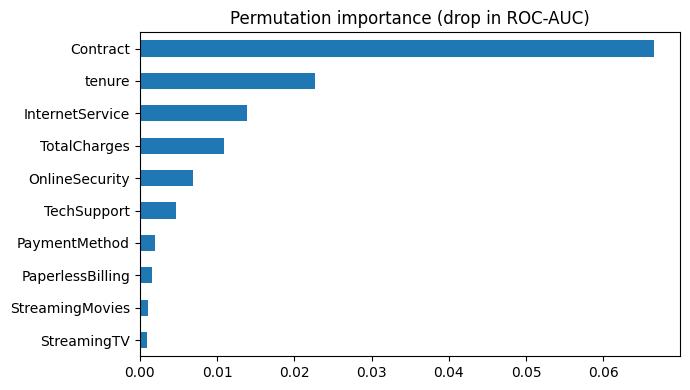

Contract            0.066581
tenure              0.022661
InternetService     0.013804
TotalCharges        0.010883
OnlineSecurity      0.006834
TechSupport         0.004684
PaymentMethod       0.001952
PaperlessBilling    0.001589
dtype: float64


In [3]:
pi = permutation_importance(model, Xte, yte, scoring='roc_auc', n_repeats=10, random_state=42)
imp = pd.Series(pi.importances_mean, index=Xte.columns).sort_values()
imp.tail(10).plot.barh(figsize=(7,4), title='Permutation importance (drop in ROC-AUC)')
plt.tight_layout(); plt.savefig('figures/task3_perm_importance.png', dpi=200); plt.show(); print(imp.sort_values(ascending=False).head(8))

## 2. SHAP: global summary and local explanation

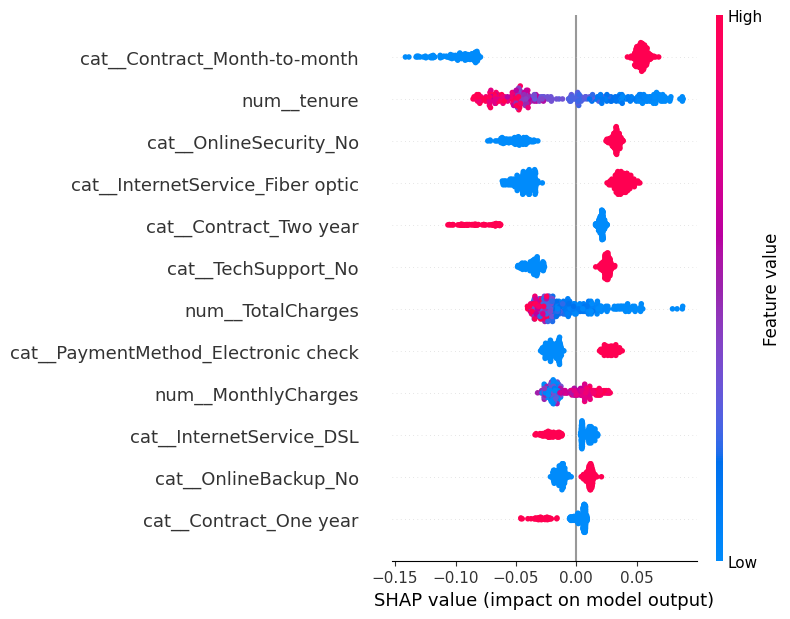

cat__Contract_Month-to-month           0.071615
num__tenure                            0.045731
cat__OnlineSecurity_No                 0.040940
cat__InternetService_Fiber optic       0.040696
cat__Contract_Two year                 0.034980
cat__TechSupport_No                    0.030231
num__TotalCharges                      0.023321
cat__PaymentMethod_Electronic check    0.022220
dtype: float64


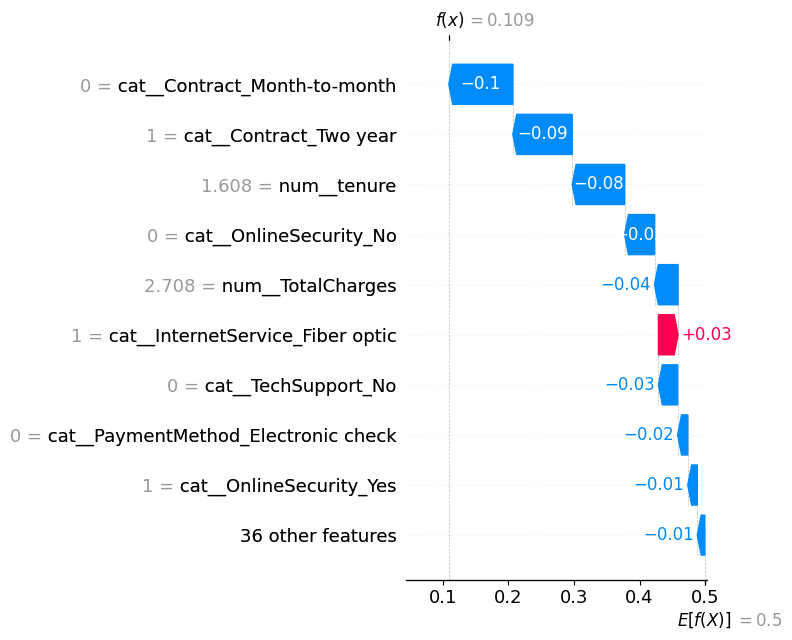

In [4]:
bg = shap.sample(Ttr, 100, random_state=1)
N = 300
if hasattr(clf,'feature_importances_'):
    expl = shap.TreeExplainer(clf); sv = expl(Tte[:N], check_additivity=False)
    vals = sv.values[...,1] if sv.values.ndim==3 else sv.values
    base = sv.base_values[...,1] if np.ndim(sv.base_values)==2 else sv.base_values
else:
    expl = shap.LinearExplainer(clf, bg); sv = expl(Tte[:N]); vals, base = sv.values, sv.base_values
exp = shap.Explanation(values=vals, base_values=base, data=Tte[:N], feature_names=list(names))
shap.summary_plot(vals, Tte[:N], feature_names=names, show=False, max_display=12)
plt.tight_layout(); plt.savefig('figures/task3_shap_summary.png', dpi=200, bbox_inches='tight'); plt.show()
shap_top = pd.Series(np.abs(vals).mean(0), index=names).sort_values(ascending=False).head(8); print(shap_top)
i = 0   # customer index to explain locally
shap.plots.waterfall(exp[i], max_display=10, show=False)
plt.tight_layout(); plt.savefig('figures/task3_shap_local.png', dpi=200, bbox_inches='tight'); plt.show()

## 3. LIME local explanation for the same customer

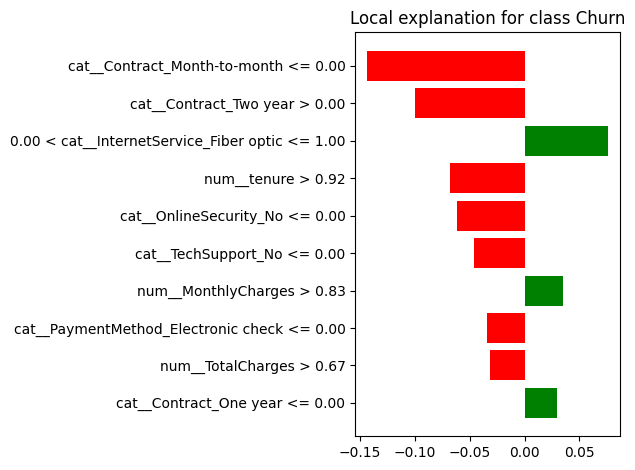

[('cat__Contract_Month-to-month <= 0.00', -0.14350348315824274), ('cat__Contract_Two year > 0.00', -0.10040032534380111), ('0.00 < cat__InternetService_Fiber optic <= 1.00', 0.07610560880143934), ('num__tenure > 0.92', -0.06821103391951093), ('cat__OnlineSecurity_No <= 0.00', -0.061297781337204316), ('cat__TechSupport_No <= 0.00', -0.04652701526169985), ('num__MonthlyCharges > 0.83', 0.035066794260434096), ('cat__PaymentMethod_Electronic check <= 0.00', -0.03388611487767245), ('num__TotalCharges > 0.67', -0.031349637504003665), ('cat__Contract_One year <= 0.00', 0.029697441658948585)]
Overlap of top-10 features SHAP vs LIME for this customer: 8 / 10


In [5]:
lime = LimeTabularExplainer(Ttr, feature_names=list(names), class_names=['No churn','Churn'], mode='classification', random_state=1)
e = lime.explain_instance(Tte[i], clf.predict_proba, num_features=10)
fig = e.as_pyplot_figure(); plt.tight_layout(); plt.savefig('figures/task3_lime_local.png', dpi=200); plt.show()
print(e.as_list())
shap_local = pd.Series(vals[i], index=names).abs().sort_values(ascending=False).head(10).index
lime_feats = [f for f,_ in e.as_list()]
def base_name(s): return s.split('__')[-1]
overlap = len({base_name(a) for a in shap_local} & {base_name(next((n for n in names if n in f), f)) for f in lime_feats})
print('Overlap of top-10 features SHAP vs LIME for this customer:', overlap, '/ 10')

## 4. Bias check across sensitive groups
Sensitive attributes available: **gender** and **SeniorCitizen**. Metrics: selection rate, true positive rate (TPR), demographic parity difference (DPD), equal opportunity difference (EOD = max TPR gap).

In [6]:
from fairlearn.metrics import MetricFrame, selection_rate, true_positive_rate, demographic_parity_difference
tables = {}
def audit(pred, label):
    out={}
    for attr in ['gender','SeniorCitizen']:
        s = Xte[attr]
        mf = MetricFrame(metrics={'selection_rate':selection_rate,'TPR':true_positive_rate}, y_true=yte, y_pred=pred, sensitive_features=s)
        print(f'--- {label} | {attr}'); print(mf.by_group.round(3)); tables[(label,attr)] = mf.by_group.round(3)
        out[f'DPD ({attr})'] = demographic_parity_difference(yte, pred, sensitive_features=s)
        out[f'EOD ({attr})'] = mf.by_group['TPR'].max()-mf.by_group['TPR'].min()
    out['Accuracy']=accuracy_score(yte,pred); out['F1']=f1_score(yte,pred)
    return out
pred0 = model.predict(Xte); before = audit(pred0, 'BEFORE mitigation')

--- BEFORE mitigation | gender
        selection_rate    TPR
gender                       
Female           0.402  0.772
Male             0.413  0.818
--- BEFORE mitigation | SeniorCitizen
               selection_rate    TPR
SeniorCitizen                       
0                       0.363  0.761
1                       0.644  0.888


## 5. Mitigation: reweighing (Kamiran & Calders) + retraining
Each (group, label) combination gets weight = expected / observed frequency, making group membership and outcome statistically independent in the training data.

In [7]:
def reweigh(df, y, attr):
    w = np.ones(len(df)); y = np.asarray(y)
    for g in df[attr].unique():
        for c in (0,1):
            m = (df[attr]==g).values & (y==c)
            if m.sum(): w[m] = ((df[attr]==g).mean()*(y==c).mean())/m.mean()
    return w
w = reweigh(Xtr,ytr,'gender')*reweigh(Xtr,ytr,'SeniorCitizen')
new = clone(model); new.fit(Xtr, ytr, clf__sample_weight=w)
pred1 = new.predict(Xte); after = audit(pred1, 'AFTER mitigation')
tab = pd.DataFrame({'Before':before,'After':after}).round(4); display(tab); tab.to_csv('figures/task3_fairness_table.csv')

--- AFTER mitigation | gender
        selection_rate    TPR
gender                       
Female           0.405  0.756
Male             0.420  0.829
--- AFTER mitigation | SeniorCitizen
               selection_rate    TPR
SeniorCitizen                       
0                        0.37  0.764
1                        0.64  0.867


,Before,After
DPD (gender),0.0110,0.0150
EOD (gender),0.0457,0.0723
DPD (SeniorCitizen),0.2810,0.2698
EOD (SeniorCitizen),0.1269,0.1029
Accuracy,0.7488,0.7424
F1,0.6266,0.6199


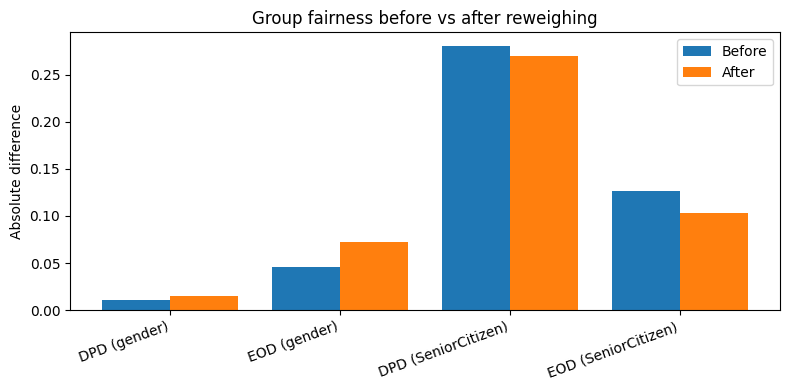

In [8]:
keys=[k for k in before if k.startswith(('DPD','EOD'))]
x=np.arange(len(keys)); plt.figure(figsize=(8,4))
plt.bar(x-0.2,[abs(before[k]) for k in keys],0.4,label='Before'); plt.bar(x+0.2,[abs(after[k]) for k in keys],0.4,label='After')
plt.xticks(x,keys,rotation=20,ha='right'); plt.ylabel('Absolute difference'); plt.title('Group fairness before vs after reweighing'); plt.legend()
plt.tight_layout(); plt.savefig('figures/task3_fairness_before_after.png', dpi=200); plt.show()

## 6. Write-up (auto-generated from the results above)

In [9]:
top_perm = ', '.join(imp.sort_values(ascending=False).head(5).index)
top_shap = ', '.join(dict.fromkeys(n.split('__')[-1].rsplit('_',1)[0] if n.startswith('cat') else n.split('__')[-1] for n in shap_top.index))
rows = '\n'.join(f'| {k} | {before[k]:.4f} | {after[k]:.4f} |' for k in before)
gap = lambda d,k: abs(d[k])
worst = max(keys, key=lambda k: gap(before,k))
shrunk = [k for k in keys if gap(after,k) < gap(before,k)]
grew = [k for k in keys if gap(after,k) > gap(before,k)]
writeup = f'''# Task 3 Write-up: Explainability, Bias Checks and Mitigation

## Model audited
{type(clf).__name__} churn classifier from Task 1 (test ROC-AUC {roc_auc_score(yte, model.predict_proba(Xte)[:,1]):.3f}).

## Explainability
- **Permutation importance** (drop in ROC-AUC): top features = {top_perm}.
- **SHAP** (mean |SHAP|, global): top drivers = {top_shap}.
- These make business sense: contract type and tenure dominate (month-to-month and short-tenure customers churn most, as the EDA in Task 1 also showed), followed by service-related features such as internet service type, online security and tech support. No sensitive attribute is among the top drivers.
- **Local explanation**: for test customer #{i} SHAP and LIME were compared; their top-10 feature lists overlap on {overlap}/10 features. LIME is a local linear surrogate, SHAP is based on Shapley values, so small differences in ranking are expected; agreement on the main drivers increases confidence.

## Bias checks (sensitive attributes: gender, SeniorCitizen)
Largest gap before mitigation: **{worst}** = {before[worst]:.3f}. Full comparison (DPD = demographic parity difference, EOD = equal-opportunity difference / TPR gap):

| Metric | Before | After reweighing |
|---|---|---|
{rows}

Gaps that shrank after reweighing: {', '.join(shrunk) if shrunk else 'none'}. Gaps that grew slightly: {', '.join(grew) if grew else 'none'} (small in absolute terms and within the noise expected for a 1,409-row test set, but they show reweighing is not a guaranteed fix and must be re-audited). Note that part of any SeniorCitizen gap reflects a genuine difference in churn base rates
(seniors churn more in the data), so a selection-rate gap is not automatically unfair; TPR/EOD shows whether the model finds real churners equally well in each group.
Accuracy changed from {before['Accuracy']:.3f} to {after['Accuracy']:.3f} and F1 from {before['F1']:.3f} to {after['F1']:.3f}, i.e. the accuracy/fairness trade-off is {'small' if abs(before['Accuracy']-after['Accuracy'])<0.02 else 'noticeable'}.

## Mitigation recommendations
1. **Reweighing** (done above) or other pre-processing; re-audit after every retrain.
2. **Per-group decision thresholds** to equalise TPR, only where legally and ethically acceptable.
3. **Check proxy features** (e.g. partner/dependents, tenure, plan type) that may encode age or gender even if the sensitive column is removed.
4. **More representative data** and larger samples for small groups (senior citizens are ~16% of customers), so metrics have narrow confidence intervals.
5. **Human review** for high-impact actions; churn offers are low-stakes, but the same model must not be reused for credit or service denial.
6. **Governance**: publish a model card (intended use, metrics per group, limitations), monitor drift and group metrics in production, and allow customers to contest decisions.
'''
open('Task3_Writeup.md','w').write(writeup); print(writeup)

# Task 3 Write-up: Explainability, Bias Checks and Mitigation

## Model audited
RandomForestClassifier churn classifier from Task 1 (test ROC-AUC 0.842).

## Explainability
- **Permutation importance** (drop in ROC-AUC): top features = Contract, tenure, InternetService, TotalCharges, OnlineSecurity.
- **SHAP** (mean |SHAP|, global): top drivers = Contract, tenure, OnlineSecurity, InternetService, TechSupport, TotalCharges, PaymentMethod.
- These make business sense: contract type and tenure dominate (month-to-month and short-tenure customers churn most, as the EDA in Task 1 also showed), followed by service-related features such as internet service type, online security and tech support. No sensitive attribute is among the top drivers.
- **Local explanation**: for test customer #0 SHAP and LIME were compared; their top-10 feature lists overlap on 8/10 features. LIME is a local linear surrogate, SHAP is based on Shapley values, so small differences in ranking are expected; agreement on 

In [10]:
try:
    from google.colab import files
    import glob
    for f in ['Task3_Writeup.md']+glob.glob('figures/task3_*'): files.download(f)
except ImportError: pass